# 🚚 Nismara Smart Audit: Bulk Check Jarak Tempuh Driver
Notebook ini digunakan untuk **mengaudit seluruh anggota armada Nismara (`driverlinks`)**, mengevaluasi pemenuhan target minimum jarak tempuh (misal **2.500 KM / bulan**) dari koleksi `jobhistories`, serta memeriksa status cuti/izin (`isOnLeave: true`) dan kelengkapan akun pada database `users`.

### 1. Install & Import Dependencies
Menyiapkan library `pymongo`, `pandas`, `tabulate`, dan `matplotlib`.

In [12]:
!pip install pymongo python-dotenv pandas tabulate matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import os
import sys
import datetime
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pymongo import MongoClient

# Load file .env
load_dotenv()
MONGODB_URI = os.getenv("MONGODB_URI", "mongodb://localhost:27017/nismara_db")

print("✅ Library dan Environment berhasil dimuat.")

✅ Library dan Environment berhasil dimuat.


### 2. Parameter Audit (Bulan, Tahun, & Target Minimum KM)
Silakan tentukan bulan, tahun, serta target minimum jarak tempuh bulanan.

In [ ]:
# =============================================================================
# ⚙️ PARAMETER AUDIT
# =============================================================================
BULAN = 8          # Bulan yang ingin diaudit (1 = Januari, ..., 7 = Juli, dll)
TAHUN = 2026       # Tahun audit
MIN_KM = 2500      # Target minimum jarak tempuh per bulan (KM)
GUILD_ID = None    # Isi misal '863959415702028318' atau biarkan None untuk seluruh driver
# =============================================================================

MONTH_NAMES = [
    "Januari", "Februari", "Maret", "April", "Mei", "Juni",
    "Juli", "Agustus", "September", "Oktober", "November", "Desember"
]
NAMA_BULAN = MONTH_NAMES[BULAN - 1] if 1 <= BULAN <= 12 else f"Bulan {BULAN}"

# Tentukan batas tanggal awal dan akhir (UTC)
START_DATE = datetime.datetime(TAHUN, BULAN, 1, 0, 0, 0, tzinfo=datetime.timezone.utc)
if BULAN == 12:
    NEXT_MONTH = datetime.datetime(TAHUN + 1, 1, 1, 0, 0, 0, tzinfo=datetime.timezone.utc)
else:
    NEXT_MONTH = datetime.datetime(TAHUN, BULAN + 1, 1, 0, 0, 0, tzinfo=datetime.timezone.utc)
END_DATE = NEXT_MONTH - datetime.timedelta(microseconds=1)

print(f"📅 Periode Audit : {START_DATE.strftime('%Y-%m-%d')} s/d {END_DATE.strftime('%Y-%m-%d')} ({NAMA_BULAN} {TAHUN})")
print(f"🎯 Target Min KM : {MIN_KM:,} KM")

📅 Periode Audit : 2026-07-01 s/d 2026-07-31 (Juli 2026)
🎯 Target Min KM : 2,500 KM


### 3. Eksekusi Ekstraksi Data dari MongoDB
Mengambil data dari 3 koleksi utama:
1. **`driverlinks`**: Master daftar driver & Discord ID
2. **`users`**: Informasi akun, nama web, dan status cuti (`isOnLeave`)
3. **`jobhistories`**: Agregasi total jarak tempuh (`distanceKm`) & jumlah job berstatus `COMPLETED` pada bulan tersebut.

In [15]:
client = MongoClient(MONGODB_URI)
db = client.get_default_database()

try:
    # 1. Tarik seluruh driverlink
    driver_filter = {}
    if GUILD_ID is not None and str(GUILD_ID).strip() != "":
        guild_str = str(GUILD_ID).strip()
        # Handle baik tipe string maupun integer di DB
        driver_filter["guildId"] = {"$in": [guild_str, int(guild_str)] if guild_str.isdigit() else [guild_str]}

    driverlinks = list(db["driverlinks"].find(driver_filter))
    print(f"🔍 Ditemukan {len(driverlinks)} driver di koleksi 'driverlinks'.")

    # 2. Tarik seluruh data users untuk lookup
    users = list(db["users"].find({}))
    user_by_discord = {str(u.get("discordId")): u for u in users if u.get("discordId")}
    user_by_trucky = {str(u.get("truckyId")): u for u in users if u.get("truckyId") is not None}
    print(f"👥 Ditemukan {len(users)} user di koleksi 'users'.")

    # 3. Agregasi jobhistories bulan bersangkutan (Status: COMPLETED)
    job_pipeline = [
        {
            "$match": {
                "jobStatus": "COMPLETED",
                "createdAt": {
                    "$gte": START_DATE,
                    "$lte": END_DATE
                }
            }
        },
        {
            "$group": {
                "_id": {
                    "driverId": "$driverId",
                    "truckyId": "$truckyId"
                },
                "totalKm": {"$sum": {"$ifNull": ["$distanceKm", 0]}},
                "jobCount": {"$sum": 1}
            }
        }
    ]
    job_aggr = list(db["jobhistories"].aggregate(job_pipeline))
    print(f"📦 Agregasi jobhistories selesai: {len(job_aggr)} grup pengiriman ditemukan.")

    mileage_by_driver = {}
    mileage_by_trucky = {}

    for item in job_aggr:
        d_id = str(item["_id"].get("driverId")) if item["_id"].get("driverId") else None
        t_id = str(item["_id"].get("truckyId")) if item["_id"].get("truckyId") else None
        km = item.get("totalKm", 0)
        cnt = item.get("jobCount", 0)

        if d_id:
            curr = mileage_by_driver.get(d_id, {"totalKm": 0, "jobCount": 0})
            mileage_by_driver[d_id] = {"totalKm": curr["totalKm"] + km, "jobCount": curr["jobCount"] + cnt}
        if t_id:
            curr = mileage_by_trucky.get(t_id, {"totalKm": 0, "jobCount": 0})
            mileage_by_trucky[t_id] = {"totalKm": curr["totalKm"] + km, "jobCount": curr["jobCount"] + cnt}

    # 4. Evaluasi setiap driverlink
    results = []
    for dl in driverlinks:
        user_id_str = str(dl.get("userId", ""))
        trucky_id_str = str(dl.get("truckyId", ""))

        user_doc = user_by_discord.get(user_id_str) or user_by_trucky.get(trucky_id_str)
        has_user_doc = user_doc is not None
        is_on_leave = bool(user_doc.get("isOnLeave", False)) if user_doc else False
        user_name = (user_doc.get("name") if user_doc else None) or dl.get("truckyName") or "-"

        # Perhitungan KM
        total_km = 0.0
        job_count = 0
        if user_id_str in mileage_by_driver:
            stat = mileage_by_driver[user_id_str]
            total_km = stat["totalKm"]
            job_count = stat["jobCount"]
        elif trucky_id_str in mileage_by_trucky:
            stat = mileage_by_trucky[trucky_id_str]
            total_km = stat["totalKm"]
            job_count = stat["jobCount"]

        # Kategori Status
        if total_km >= MIN_KM:
            status_kategori = "MEMENUHI TARGET" if has_user_doc else "MEMENUHI (NO USER DOC)"
            status_code = "PASSED"
        else:
            if not has_user_doc:
                status_kategori = "TIDAK ADA DATA USERS"
                status_code = "MISSING_USER"
            elif is_on_leave:
                status_kategori = "SEDANG CUTI (IZIN)"
                status_code = "FAILED_ON_LEAVE"
            else:
                status_kategori = "TIDAK CAPAI & AKTIF"
                status_code = "FAILED_ACTIVE"

        shortage_km = max(0.0, MIN_KM - total_km)

        results.append({
            "Trucky Name": dl.get("truckyName", "-"),
            "Trucky ID": dl.get("truckyId", "-"),
            "Discord ID": user_id_str,
            "Nama Web": user_name,
            "Total KM": round(total_km, 2),
            "Jumlah Jobs": job_count,
            "Kekurangan KM": round(shortage_km, 2),
            "Sedang Cuti": "YA" if is_on_leave else "TIDAK",
            "Ada di Users DB": "YA" if has_user_doc else "TIDAK",
            "Status": status_kategori,
            "status_code": status_code
        })

    kolom_utama = [
        "Trucky Name", "Trucky ID", "Discord ID", "Nama Web", 
        "Total KM", "Jumlah Jobs", "Kekurangan KM", "Sedang Cuti", 
        "Ada di Users DB", "Status", "status_code"
    ]
    if results:
        df_all = pd.DataFrame(results).sort_values(by="Total KM", ascending=True).reset_index(drop=True)
    else:
        df_all = pd.DataFrame(columns=kolom_utama)

    print(f"✅ Berhasil memproses {len(df_all)} data driver ke DataFrame.")
finally:
    client.close()

🔍 Ditemukan 131 driver di koleksi 'driverlinks'.
👥 Ditemukan 92 user di koleksi 'users'.
📦 Agregasi jobhistories selesai: 73 grup pengiriman ditemukan.
✅ Berhasil memproses 131 data driver ke DataFrame.


### 4. 📊 Ringkasan Eksekutif & KPI Bulanan

In [16]:
total_driver = len(df_all)
df_passed = df_all[df_all["status_code"].isin(["PASSED", "MEMENUHI (NO USER DOC)"])] if not df_all.empty else pd.DataFrame()
df_failed_active = df_all[df_all["status_code"] == "FAILED_ACTIVE"] if not df_all.empty else pd.DataFrame()
df_failed_leave = df_all[df_all["status_code"] == "FAILED_ON_LEAVE"] if not df_all.empty else pd.DataFrame()
df_missing_user = df_all[df_all["Ada di Users DB"] == "TIDAK"] if not df_all.empty else pd.DataFrame()

total_km_armada = df_all["Total KM"].sum() if not df_all.empty else 0
total_jobs_armada = df_all["Jumlah Jobs"].sum() if not df_all.empty else 0
avg_km_driver = total_km_armada / total_driver if total_driver > 0 else 0

summary_data = {
    "Metrik": [
        "Total Driverlink Terdaftar",
        f"✅ Memenuhi Target (>= {MIN_KM:,} KM)",
        f"🚨 Tidak Capai & Aktif (Wajib Review)",
        f"🏖️ Tidak Capai & Sedang Cuti (Izin)",
        "⚠️ Driver Belum Ada di DB Users",
        "🛣️ Total Jarak Tempuh Armada",
        "📦 Total Pengiriman (Jobs)",
        "📈 Rata-rata Jarak Tempuh per Driver"
    ],
    "Nilai": [
        f"{total_driver} driver",
        f"{len(df_passed)} driver ({(len(df_passed)/total_driver*100):.1f}%)" if total_driver else "0 driver",
        f"{len(df_failed_active)} driver ({(len(df_failed_active)/total_driver*100):.1f}%)" if total_driver else "0 driver",
        f"{len(df_failed_leave)} driver ({(len(df_failed_leave)/total_driver*100):.1f}%)" if total_driver else "0 driver",
        f"{len(df_missing_user)} driver ({(len(df_missing_user)/total_driver*100):.1f}%)" if total_driver else "0 driver",
        f"{total_km_armada:,.0f} KM",
        f"{total_jobs_armada:,} pengiriman",
        f"{avg_km_driver:,.0f} KM / driver"
    ]
}

pd.DataFrame(summary_data)

,Metrik,Nilai
0,Total Driverlink Terdaftar,131 driver
1,"✅ Memenuhi Target (>= 2,500 KM)",51 driver (38.9%)
2,🚨 Tidak Capai & Aktif (Wajib Review),32 driver (24.4%)
3,🏖️ Tidak Capai & Sedang Cuti (Izin),0 driver (0.0%)
4,⚠️ Driver Belum Ada di DB Users,53 driver (40.5%)
5,🛣️ Total Jarak Tempuh Armada,"1,141,205 KM"
6,📦 Total Pengiriman (Jobs),918 pengiriman
7,📈 Rata-rata Jarak Tempuh per Driver,"8,711 KM / driver"


### 5. 🚨 DAFTAR 1: Driver Aktif yang TIDAK Mencapai Target Minimum (< 2.500 KM)
> **Catatan:** Driver pada daftar ini **tidak memiliki status cuti** (`isOnLeave: false`) dan **jarak tempuhnya kurang dari 2.500 KM**. Driver ini yang perlu dievaluasi atau diberikan sanksi.

In [17]:
kolom_tampil = ["Trucky Name", "Trucky ID", "Discord ID", "Nama Web", "Total KM", "Jumlah Jobs", "Kekurangan KM"]
if not df_failed_active.empty:
    df_failed_active_tampil = df_failed_active[kolom_tampil].reset_index(drop=True)
    df_failed_active_tampil.index += 1
    print(f"🚨 Total Driver Aktif yang Kurang dari {MIN_KM:,} KM: {len(df_failed_active_tampil)} driver\n")
    display(df_failed_active_tampil)
else:
    print("🎉 Semua driver aktif berhasil mencapai batas minimum jarak tempuh!")

🚨 Total Driver Aktif yang Kurang dari 2,500 KM: 32 driver



,Trucky Name,Trucky ID,Discord ID,Nama Web,Total KM,Jumlah Jobs,Kekurangan KM
1,Rains,181898,979476718479884379,rainslucky,0.00,0,2500.00
2,Herventhine S.O.,181897,205714486143746048,herventhine,0.00,0,2500.00
3,Big People 23,246044,731755998351458386,bigpeople,0.00,0,2500.00
4,dinosibrat,241273,785117577294512128,fatkhulanam,0.00,0,2500.00
5,MFH_Gaming,246241,876060260069154856,mfh_storee,0.00,0,2500.00
6,idraa,247406,432465949455548417,idraa,0.00,0,2500.00
7,Xean,247525,1088989514942398566,xentnt,0.00,0,2500.00
8,ogifreedom,243695,616063410655723532,ogifreedom,0.00,0,2500.00
9,Ayran,275727,758754205208281101,ayranci32,0.00,0,2500.00
10,Mia,280148,894556701959815178,maybe_baby69,0.00,0,2500.00


### 6. 🏖️ DAFTAR 2: Driver yang TIDAK Mencapai Target tetapi Sedang CUTI (`isOnLeave: true`)
> **Catatan:** Driver pada daftar ini di bawah target namun **memiliki izin/cuti resmi** sehingga dimaklumi.

In [18]:
if not df_failed_leave.empty:
    df_failed_leave_tampil = df_failed_leave[kolom_tampil].reset_index(drop=True)
    df_failed_leave_tampil.index += 1
    print(f"🏖️ Total Driver Sedang Cuti di Bawah Target: {len(df_failed_leave_tampil)} driver\n")
    display(df_failed_leave_tampil)
else:
    print("ℹ️ Tidak ada driver berstatus cuti yang berada di bawah target jarak tempuh.")

ℹ️ Tidak ada driver berstatus cuti yang berada di bawah target jarak tempuh.


### 7. ⚠️ DAFTAR 3: Driverlink yang BELUM Terdata di Database `users`
> **Catatan:** Driver terdaftar di bot/Trucky tetapi akun Discord-nya belum terhubung ke database website.

In [19]:
kolom_missing = ["Trucky Name", "Trucky ID", "Discord ID", "Total KM", "Jumlah Jobs", "Status"]
if not df_missing_user.empty:
    df_missing_tampil = df_missing_user[kolom_missing].reset_index(drop=True)
    df_missing_tampil.index += 1
    print(f"⚠️ Total Driver Belum Terdaftar di Users DB: {len(df_missing_tampil)} driver\n")
    display(df_missing_tampil)
else:
    print("✅ Seluruh driverlink sudah memiliki profil di database users.")

⚠️ Total Driver Belum Terdaftar di Users DB: 53 driver



,Trucky Name,Trucky ID,Discord ID,Total KM,Jumlah Jobs,Status
1,Fhay_FM,246186,1448928869485641772,0.00,0,TIDAK ADA DATA USERS
2,BangBT,246203,249436516210704385,0.00,0,TIDAK ADA DATA USERS
3,Jejaka Tampan,246187,336615241079324672,0.00,0,TIDAK ADA DATA USERS
4,Piksen,246188,1256455808665784390,0.00,0,TIDAK ADA DATA USERS
5,tahu,246590,205980234078486528,0.00,0,TIDAK ADA DATA USERS
6,PackPoy,246319,503793384083947521,0.00,0,TIDAK ADA DATA USERS
7,abidin,238208,769524203056529428,0.00,0,TIDAK ADA DATA USERS
8,BLACKNAZI,246331,318741930559406084,0.00,0,TIDAK ADA DATA USERS
9,Primaaafm,246285,1449636274150314098,0.00,0,TIDAK ADA DATA USERS
10,AlFarizei,246689,686482593134542848,0.00,0,TIDAK ADA DATA USERS


### 8. ✅ DAFTAR 4: Top Driver yang Memenuhi Target (>= 2.500 KM)

In [20]:
if not df_passed.empty:
    df_passed_tampil = df_passed[["Trucky Name", "Trucky ID", "Discord ID", "Nama Web", "Total KM", "Jumlah Jobs"]].sort_values(by="Total KM", ascending=False).reset_index(drop=True)
    df_passed_tampil.index += 1
    print(f"✅ Total Driver Memenuhi Target: {len(df_passed_tampil)} driver\n")
    display(df_passed_tampil.head(20))  # Tampilkan Top 20
else:
    print("ℹ️ Belum ada driver yang mencapai target pada periode ini.")

✅ Total Driver Memenuhi Target: 51 driver



,Trucky Name,Trucky ID,Discord ID,Nama Web,Total KM,Jumlah Jobs
1,Srinay,246373,369123825289265152,srinay,112808.94,67
2,Rully,101740,384287010883502081,rully1205,91651.45,78
3,LegenSegerr,192298,456696560416194570,legensegerr,87971.40,37
4,yoga.prasetya.utama11,249663,460737485719207947,Codename_Zero,72830.18,51
5,Muhammad Verrell,242319,465090189262585866,Frankenstein,68607.92,55
6,baplang100,59783,656562242652864543,baplang100,67994.38,46
7,ciminyaw,246402,377833394131697674,ciminyaw,52490.49,16
8,Aldinuh,257058,498784834508947459,Pak Dino,46809.00,33
9,dymastoo,256075,789119031286300672,Ayaneru,40328.94,17
10,marvelalfatih,272761,1285073617817702400,Marvel Al Fatih,38233.39,38


### 9. 📈 Visualisasi Grafik Status Driver

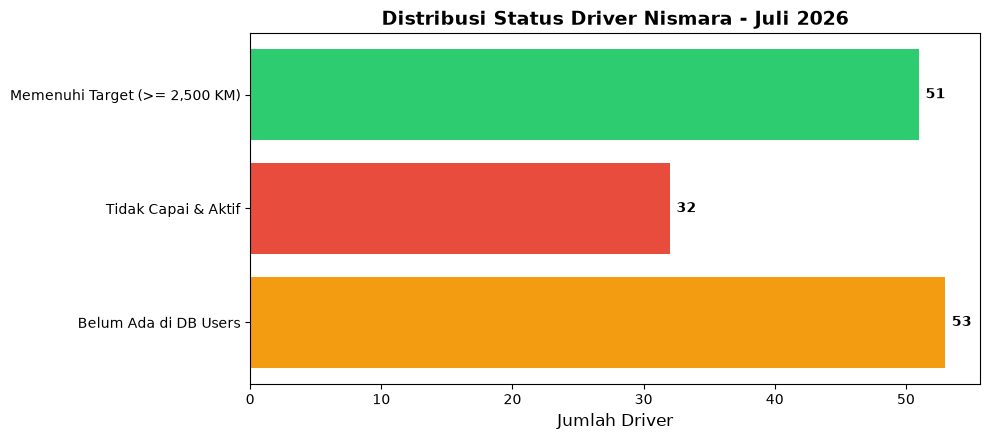

In [21]:
kategori_counts = {
    f"Memenuhi Target (>= {MIN_KM:,} KM)": len(df_passed),
    "Tidak Capai & Aktif": len(df_failed_active),
    "Tidak Capai & Cuti": len(df_failed_leave),
    "Belum Ada di DB Users": len(df_missing_user)
}

labels = [k for k, v in kategori_counts.items() if v > 0]
values = [v for v in kategori_counts.values() if v > 0]
colors = ["#2ecc71", "#e74c3c", "#f39c12", "#95a5a6"]

if values:
    plt.figure(figsize=(10, 4.5))
    plt.barh(labels, values, color=colors[:len(labels)])
    plt.xlabel("Jumlah Driver", fontsize=12)
    plt.title(f"Distribusi Status Driver Nismara - {NAMA_BULAN} {TAHUN}", fontsize=14, fontweight="bold")
    for index, value in enumerate(values):
        plt.text(value + 0.5, index, str(value), va="center", fontweight="bold")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada data untuk divisualisasikan.")

### 10. 💾 Export Laporan ke File CSV & Markdown
Menyimpan hasil audit ke file CSV dan Markdown untuk dibagikan ke manajemen atau Discord.

In [22]:
REPORT_DIR = os.path.join("report", f"{TAHUN}-{BULAN:02d}")
os.makedirs(REPORT_DIR, exist_ok=True)
csv_filename = os.path.join(REPORT_DIR, f"audit_driver_{NAMA_BULAN.lower()}_{TAHUN}.csv")
if not df_all.empty:
    export_df = df_all.drop(columns=["status_code"]) if "status_code" in df_all.columns else df_all
    export_df.to_csv(csv_filename, index=False, encoding="utf-8-sig")
    print(f"✅ Data berhasil diexport ke CSV: {csv_filename}")

# Buat laporan Markdown
md_filename = os.path.join(REPORT_DIR, f"audit_driver_{NAMA_BULAN.lower()}_{TAHUN}.md")
with open(md_filename, "w", encoding="utf-8") as f:
    f.write(f"# 🚚 Laporan Audit Jarak Tempuh Driver Nismara Transport\n")
    f.write(f"**Periode:** {NAMA_BULAN} {TAHUN} ({START_DATE.strftime('%Y-%m-%d')} s/d {END_DATE.strftime('%Y-%m-%d')})  \n")
    f.write(f"**Target Minimum:** {MIN_KM:,} KM / Bulan  \n\n")
    f.write(f"---\n\n")
    f.write(f"## 📊 Ringkasan Eksekutif\n")
    f.write(f"- **Total Driverlink Terdaftar:** {total_driver} driver\n")
    f.write(f"- **Memenuhi Target (>= {MIN_KM:,} KM):** {len(df_passed)} driver ({(len(df_passed)/total_driver*100):.1f}%)\n" if total_driver else "")
    f.write(f"- **Tidak Capai & Aktif (Wajib Review):** {len(df_failed_active)} driver ({(len(df_failed_active)/total_driver*100):.1f}%)\n" if total_driver else "")
    f.write(f"- **Tidak Capai & Cuti (Izin):** {len(df_failed_leave)} driver ({(len(df_failed_leave)/total_driver*100):.1f}%)\n" if total_driver else "")
    f.write(f"- **Belum Ada di DB Users:** {len(df_missing_user)} driver\n")
    f.write(f"- **Total KM Armada:** {total_km_armada:,.0f} KM ({total_jobs_armada:,} Pengiriman)\n\n")
    f.write(f"---\n\n")
    f.write(f"## 🚨 Driver Tidak Capai Target (Aktif / Tanpa Izin)\n")
    if not df_failed_active.empty:
        f.write(df_failed_active[kolom_tampil].to_markdown(index=False))
    else:
        f.write("*Semua driver aktif memenuhi target minimum!*\n")
    f.write(f"\n\n---\n\n")
    f.write(f"## 🏖️ Driver Tidak Capai Target (Sedang Cuti Resmi)\n")
    if not df_failed_leave.empty:
        f.write(df_failed_leave[kolom_tampil].to_markdown(index=False))
    else:
        f.write("*Tidak ada driver cuti yang di bawah target.*\n")

print(f"✅ Laporan Markdown berhasil disimpan ke: {md_filename}")

✅ Data berhasil diexport ke CSV: audit_driver_juli_2026.csv
✅ Laporan Markdown berhasil disimpan ke: audit_driver_juli_2026.md
